# v8 environment-option results (Oct 31 - Nov 1, 2026)

Views the eg15 runs launched on Oct 31 (the 512M one-factor wave, the 2B wave and the overnight queue)
and the Nov 1 morning queue (frontier coefficient 10, frontier-surface, width, no-shaping controls,
larger world at 6,000 steps, view 21x15 at 4B).
Each run directory holds `curve.json` (validation every checkpoint), `summary.json`, `protocol.json`
and `diag.json` (stockpiling diagnostic on the final checkpoint). All evaluations use the same 128
validation worlds (23,000,001-23,000,128); scores are achievements out of 32.

Run with pandas and matplotlib, e.g. from the repo root:

    uv run --no-project --with pandas,matplotlib,jupyterlab jupyter lab notebooks/v8_env_results_2026_10_31.ipynb

To refresh data from eg15 (curves, summaries, protocols, diagnostics only):

    rsync -a -e "ssh -J decidueye" --include='*/' --include='curve.json' --include='summary.json' \
      --include='protocol.json' --include='diag.json' --exclude='*' \
      mvohl@cv350-rck-g03-c01-08.rck.dcgpu:Projects/RL/experiments/<study>/ experiments/eg15/<study>/

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../experiments/eg15") if Path("../experiments/eg15").exists() else Path("experiments/eg15")
STUDIES = {  # label -> directory under DATA; add new studies here
    "512M wave": "eg15-envopt-v7-20261027",
    "2B wave": "eg15-envopt2b-v8-20261101",
    "overnight": "eg15-overnight-v8-20261101",
    "Nov 1 morning": "eg15-queue-v8-20261101b",   # in progress: unfinished runs show their latest checkpoint
}
# Library build directory (or overnight job-name prefix) -> environment variant.
VARIANTS = {
    "build-v8": "v8 default (= v7)", "build-v8-ore200": "ore 2x", "build-v8-ore300": "ore 3x",
    "build-v8-tree200": "trees 2x", "build-v8-ore300-tree200": "ore 3x + trees 2x",
    "build-v8-view21": "view 21x15", "build-v8-real": "realistic (ore 3x + trees 2x + view 21x15)",
    "build-v8-w256": "world 256x96", "build-v8-o3t2-inv": "ore 3x + trees 2x + log inventory",
    "build-v8-real-inv": "realistic + log inventory",
    # overnight job-name prefixes
    "o3t2": "ore 3x + trees 2x", "o3t2inv": "ore 3x + trees 2x + log inventory",
    "real": "realistic (ore 3x + trees 2x + view 21x15)", "realinv": "realistic + log inventory",
    "w256": "world 256x96",
    "w256o3t2": "world 256x96 + ore 3x + trees 2x", "best": "ore 3x + trees 2x + log inventory",
    "view21": "view 21x15",
}
HARD = ["craft anvil", "craft metal sword", "craft iron pickaxe", "craft gold pickaxe",
        "craft iron chainmail", "craft wood breastplate", "return to surface"]

In [2]:
def variant_of(group_dir: str) -> str:
    head, _, tail = group_dir.rpartition("-")      # strip "-g3" (GPU) or "-2001" (seed) suffixes
    name = head if tail.lstrip("g").isdigit() else group_dir
    if name in VARIANTS:
        return VARIANTS[name]
    prefix = name.split("_")[0]          # overnight job names, e.g. o3t2inv_fn_unimix-2001
    return VARIANTS.get(prefix, name)

def arm_of(cfg: dict, episode_steps: int) -> str:
    parts = [f"pot {cfg['potential_coef']:g}" + (f" {cfg['potential_mode']}" if cfg["potential_mode"] != "mean" else "")]
    if cfg.get("novelty_coef"): parts.append(f"novelty {cfg['novelty_coef']:g}")
    if cfg.get("unimix"): parts.append(f"unimix {cfg['unimix']:g}")
    if cfg.get("memory"): parts.append(f"{cfg['memory']} {cfg.get('memory_size') or 256}")
    if cfg.get("hidden"): parts.append(f"hidden {cfg['hidden']}")
    if cfg.get("lr") != 3e-4: parts.append(f"lr {cfg['lr']:g}")
    if episode_steps != 3000: parts.append(f"{episode_steps} steps")
    return ", ".join(parts)

rows, curves = [], []
for study, sub in STUDIES.items():
    for run in sorted((DATA / sub).glob("*/runs/*")):
        if not (run / "curve.json").exists():
            continue
        curve = json.loads((run / "curve.json").read_text())
        proto = json.loads((run / "protocol.json").read_text())
        ev = curve[-1]["evaluation"]
        diag = json.loads((run / "diag.json").read_text()) if (run / "diag.json").exists() else None
        key = dict(study=study, variant=variant_of(run.parent.parent.name),
                   arm=arm_of(proto["config"], proto.get("episode_steps", 3000)),
                   budget=f"{proto['actual_steps'] / 2**30:.0f}B" if proto["actual_steps"] >= 2**30
                          else f"{proto['actual_steps'] / 2**20:.0f}M",
                   seed=int(run.name.rsplit("-", 1)[1]))
        row = dict(key, steps_B=curve[-1]["steps"] / 2**30, finished=(run / "summary.json").exists(),
                   score=ev["mean_achievements"], best=max(c["evaluation"]["mean_achievements"] for c in curve),
                   deaths=ev["death_rate"], idle_steps=ev["mean_steps_after_last_achievement"],
                   **{h: ev["hits"].get(h, 0) for h in HARD})
        if diag:
            peak = diag["inventory_peak"]
            row.update(iron_bars_med=peak["iron bar"]["median"], iron_bars_max=peak["iron bar"]["max"],
                       wood_med=peak["wood"]["median"], wood_max=peak["wood"]["max"],
                       breastplate_legal_eps=diag["actions"]["craft wood breastplate"]["episodes_with_opportunity"],
                       iron_pick_legal_eps=diag["actions"]["craft iron pickaxe"]["episodes_with_opportunity"])
        rows.append(row)
        curves += [dict(key, steps_B=c["steps"] / 2**30, score=c["evaluation"]["mean_achievements"]) for c in curve]

runs = pd.DataFrame(rows)
curves = pd.DataFrame(curves)
print(f"{len(runs)} runs, {runs.finished.sum()} finished")
runs.sort_values(["study", "variant", "arm", "seed"]).reset_index(drop=True)

70 runs, 65 finished


,study,variant,arm,budget,seed,steps_B,finished,score,best,deaths,...,craft gold pickaxe,craft iron chainmail,craft wood breastplate,return to surface,iron_bars_med,iron_bars_max,wood_med,wood_max,breastplate_legal_eps,iron_pick_legal_eps
0,2B wave,ore 3x + trees 2x,pot 3,2B,2001,2.0,True,25.718750,25.859375,0.085938,...,0,0,0,1,5.0,19.0,17.0,21.0,0.0,0.0
1,2B wave,ore 3x + trees 2x,pot 3,2B,2002,2.0,True,26.109375,26.148438,0.078125,...,0,0,0,0,5.0,13.0,17.5,27.0,0.0,0.0
2,2B wave,ore 3x + trees 2x,"pot 3 frontier, novelty 0.01",2B,2001,2.0,True,27.359375,27.617188,0.046875,...,0,0,101,116,5.0,18.0,41.0,62.0,115.0,0.0
3,2B wave,ore 3x + trees 2x,"pot 3 frontier, novelty 0.01",2B,2002,2.0,True,27.601562,27.789062,0.031250,...,0,0,107,114,5.0,21.0,43.0,69.0,119.0,0.0
4,2B wave,ore 3x + trees 2x,"pot 3, hidden 1024, lr 0.0001",2B,2001,2.0,True,26.281250,26.500000,0.031250,...,0,0,0,124,5.0,14.0,17.0,22.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,overnight,realistic + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, 600...",2B,2001,2.0,True,24.781250,24.812500,0.343750,...,0,0,29,0,5.0,10.0,32.0,64.0,63.0,0.0
66,overnight,realistic + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, 600...",2B,2002,2.0,True,26.023438,26.023438,0.273438,...,0,0,53,0,6.0,20.0,38.0,69.0,84.0,0.0
67,overnight,realistic + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2001,2.0,True,25.039062,25.039062,0.304688,...,0,0,3,1,5.0,17.0,32.0,60.0,39.0,0.0
68,overnight,realistic + log inventory,"pot 3 frontier, novelty 0.01, unimix 0.01, hid...",2B,2002,2.0,True,24.867188,24.976562,0.273438,...,0,0,3,0,5.0,15.0,33.0,56.0,60.0,0.0


## Summary per study, variant and arm

Means over seeds. Hard-tier columns are validation worlds out of 128; `*_med` are median per-episode
peaks of items held at once (stockpiling); `*_legal_eps` count episodes where the craft was ever possible.

In [3]:
cols = ["score", "best", "deaths", *HARD, "iron_bars_med", "wood_med", "breastplate_legal_eps", "iron_pick_legal_eps"]
summary = (runs.groupby(["study", "variant", "arm", "budget"])
               .agg(seeds=("seed", "count"), **{c: (c, "mean") for c in cols if c in runs})
               .round(2).sort_values(["study", "score"], ascending=[True, False]))
summary

seeds  \
study         variant                                    arm                                                budget          
2B wave       ore 3x + trees 2x                          pot 3 frontier, novelty 0.01                       2B          2   
                                                         pot 3, hidden 1024, lr 0.0001                      2B          2   
                                                         pot 3, lstm 256                                    2B          2   
                                                         pot 3                                              2B          2   
              v8 default (= v7)                          pot 3                                              2B          2   
              view 21x15                                 pot 3                                              2B          2   
              realistic (ore 3x + trees 2x + view 21x15) pot 3, 6000 steps                                  2B          2   
              view 21x15                                 pot 3, hidden 512                                  2B          2   
512M wave     ore 3x + trees 2x                          pot 3                                              512M        2   
              ore 2x                                     pot 3                                              512M        2   
              realistic (ore 3x + trees 2x + view 21x15) pot 3, 6000 steps                                  512M        2   
              ore 3x                                     pot 3                                              512M        2   
              trees 2x                                   pot 3                                              512M        2   
              v8 default (= v7)                          pot 3                                              512M        2   
              view 21x15                                 pot 3                                              512M        2   
              ore 3x                                     pot 3, 6000 steps                                  512M        2   
Nov 1 morning ore 3x + trees 2x + log inventory          pot 3 frontier, novelty 0.01, unimix 0.01, hidd... 2B          2   
                                                         pot 10 frontier, novelty 0.01, unimix 0.01         2B          2   
                                                         pot 3 frontier_surface, novelty 0.01, unimix 0.01  2B          2   
              ore 3x + trees 2x                          pot 0, novelty 0.01, hidden 1024, lr 0.0001        2B          2   
                                                         pot 0, novelty 0.01, unimix 0.01                   2B          2   
                                                         pot 0                                              2B          2   
              world 256x96 + ore 3x + trees 2x           pot 3, 6000 steps                                  2B          1   
              view 21x15                                 pot 3                                              4B          1   
              world 256x96                               pot 3, 6000 steps                                  2B          1   
overnight     ore 3x + trees 2x + log inventory          pot 3 frontier, novelty 0.01, unimix 0.01          2B          4   
                                                                                                            4B          2   
              ore 3x + trees 2x                          pot 3                                              2B          2   
                                                         pot 3, unimix 0.01                                 2B          4   
              ore 3x + trees 2x + log inventory          pot 3                                              2B          2   
              realistic (ore 3x + trees 2x + view 21x15) pot 3 frontier, novelty 0.01, unimix 0.01, 6000... 2B      

## Learning curves (mean over seeds)

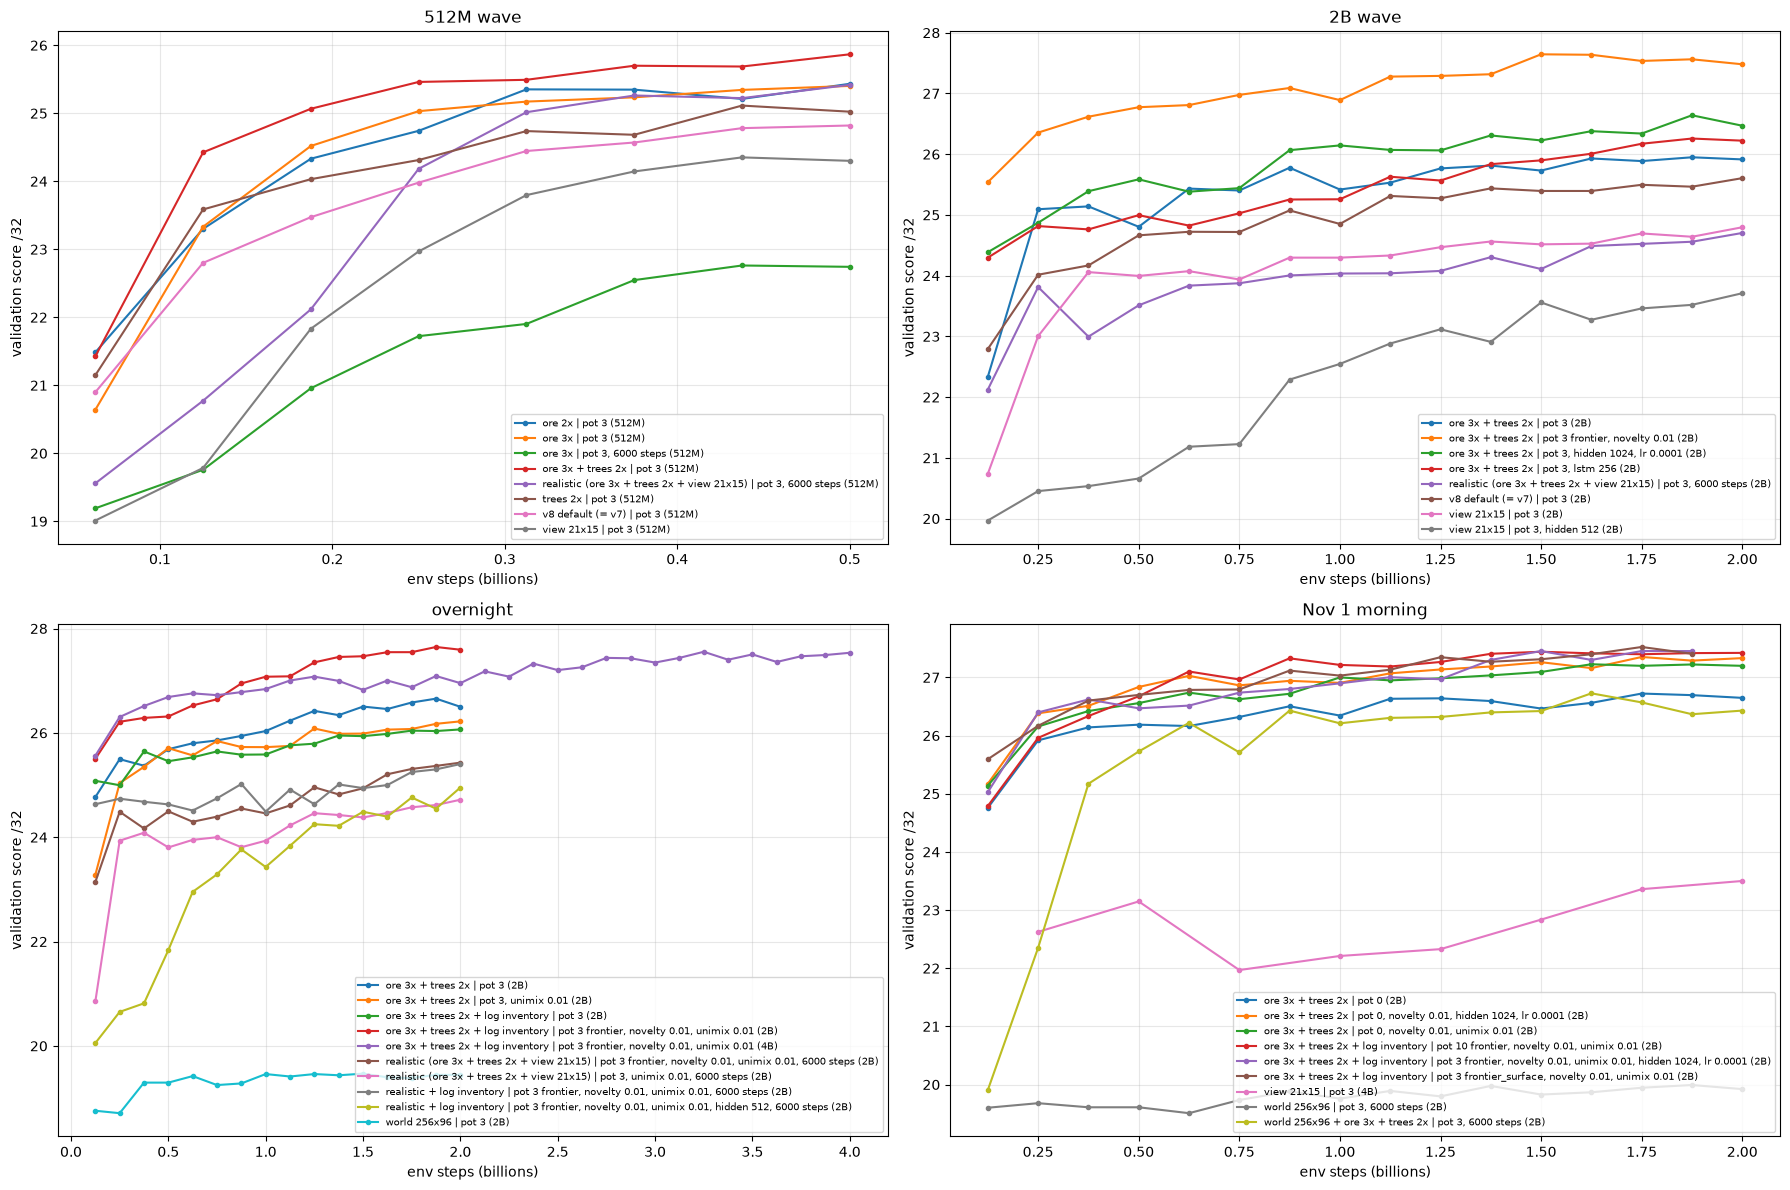

In [4]:
def plot(study, ax):
    sub = curves[curves.study == study]
    for (variant, arm, budget), g in sub.groupby(["variant", "arm", "budget"]):
        m = g.groupby("steps_B").score.mean()
        ax.plot(m.index, m.values, marker=".", label=f"{variant} | {arm} ({budget})")
    ax.set(title=study, xlabel="env steps (billions)", ylabel="validation score /32")
    ax.grid(alpha=.3)
    ax.legend(fontsize=7, loc="lower right")

ncols = 2
nrows = -(-len(STUDIES) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(9 * ncols, 6 * nrows), squeeze=False)
for study, ax in zip(STUDIES, axes.flat):
    plot(study, ax)
for ax in axes.flat[len(STUDIES):]:
    ax.set_visible(False)
plt.tight_layout()

## Hard achievements of the best arms (worlds out of 128, mean over seeds)

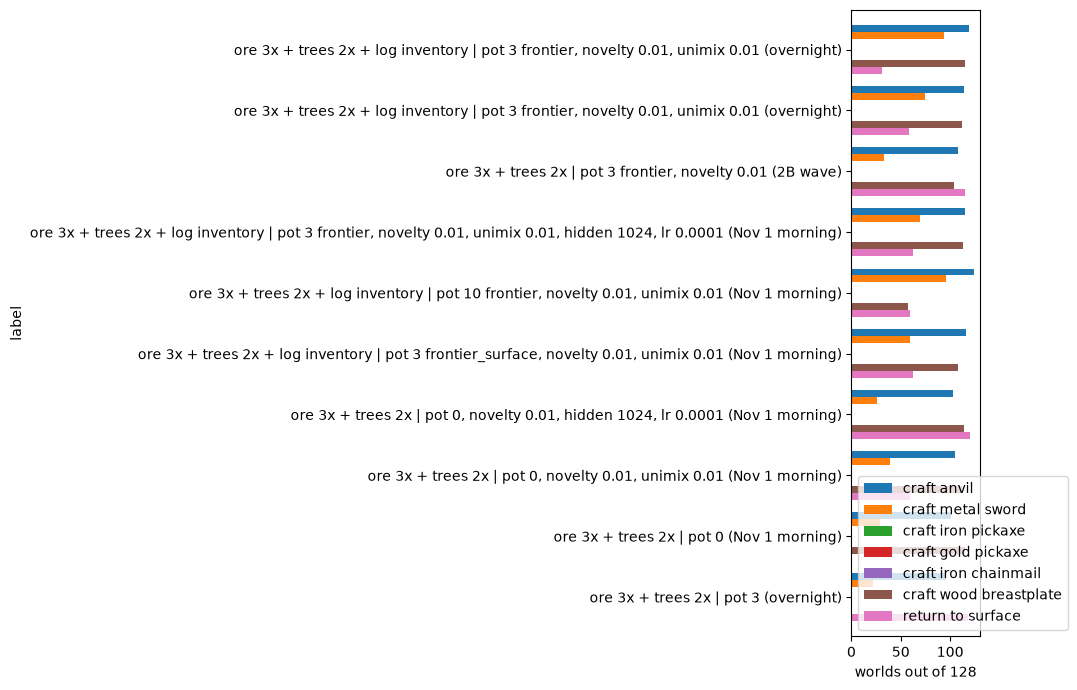

In [5]:
top = summary.reset_index().sort_values("score", ascending=False).head(10)
top = top.assign(label=top.variant + " | " + top.arm + " (" + top.study + ")").set_index("label")
top[HARD].plot.barh(figsize=(10, 7), width=.8)
plt.xlabel("worlds out of 128")
plt.gca().invert_yaxis()
plt.tight_layout()

## Per-seed detail for one variant
Change `VARIANT` to inspect seed variance (e.g. return to surface differs a lot between seeds).

In [6]:
VARIANT = "ore 3x + trees 2x + log inventory"
runs[runs.variant == VARIANT].sort_values(["arm", "seed"])[["study", "arm", "seed", "steps_B", "score", *HARD, "iron_bars_med", "wood_med"]]

,study,arm,seed,steps_B,score,craft anvil,craft metal sword,craft iron pickaxe,craft gold pickaxe,craft iron chainmail,craft wood breastplate,return to surface,iron_bars_med,wood_med
59,Nov 1 morning,"pot 10 frontier, novelty 0.01, unimix 0.01",2001,2.000,28.000000,122,73,0,0,0,114,118,6.0,41.0
60,Nov 1 morning,"pot 10 frontier, novelty 0.01, unimix 0.01",2002,2.000,26.843750,126,119,0,0,0,0,0,8.0,19.0
38,overnight,pot 3,2001,2.000,26.164062,102,13,0,0,0,0,124,5.0,17.5
39,overnight,pot 3,2002,2.000,25.968750,113,37,0,0,0,0,0,5.0,17.0
40,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2001,2.000,27.468750,106,42,0,0,0,100,122,6.0,40.0
41,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2002,2.000,27.718750,125,115,0,0,0,125,0,8.0,36.5
42,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2003,2.000,27.609375,122,110,0,0,0,118,0,8.0,46.0
43,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2004,2.000,27.578125,125,107,0,0,0,118,0,8.0,45.0
44,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2005,4.000,27.679688,124,113,0,0,0,125,0,8.0,38.0
45,overnight,"pot 3 frontier, novelty 0.01, unimix 0.01",2006,4.000,27.390625,103,36,0,0,0,98,117,5.0,40.5
